# 02 Affordability

How many households would find their electricity bill unaffordable at each threshold?

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[2]      # repo root, two levels above this folder
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.common.config import load_config
from src.common.pipeline import build

cfg = load_config()
MODE = os.environ.get("DATA_MODE")          # None = use config; "synthetic" = fake
ghs, ies, nfcm = build(MODE, save=False)

C:\Users\mmjmo\Projects\sa-electricity-nonpayment\src\common\pipeline.py:28: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  return pd.read_stata(full, convert_categoricals=False)


In [2]:
from src.a_who_pays import affordability

th = cfg["thresholds"]
affordability.threshold_table(ies, th["bill_to_income"])

,group,threshold,households_above,share_above,households_with_bill
0,All,0.08,3.976756e+06,0.242973,1.636706e+07
1,All,0.10,3.005600e+06,0.183637,1.636706e+07
2,All,0.12,2.340919e+06,0.143026,1.636706e+07


### Reading the threshold table
At a 10% line, about 3.0 million of the 16.4 million households with an electricity bill (18.4%) spend 10% or more of their income on it. At 8% the share is 24.3%, and at 12% it is 14.3%. Moving the line changes the answer a lot, which is why I report all three.

Check the pattern behind the bounds method in notebook 04: the average bill share should fall as income rises.

In [3]:
affordability.bill_share_by_decile(ies)

,decile,median_income,mean_bill_share
0,1,1598.405942,0.290522
1,2,2967.401608,0.123297
2,3,4080.158291,0.095723
3,4,5386.797486,0.076398
4,5,6971.753489,0.073024
5,6,9341.478924,0.059513
6,7,12517.937686,0.045480
7,8,17381.826671,0.036824
8,9,27854.565301,0.032011
9,10,66623.970669,0.019870


In [4]:
# Numbers used in Question 2
d1 = affordability.add_income_decile(affordability.add_bill_share(ies))
d1 = d1[(d1["has_bill"]) & (d1["decile"] == 1)]
above_half = d1.loc[d1["bill_share"] > 0.5, "weight"].sum() / d1["weight"].sum()
above_all = d1.loc[d1["bill_share"] > 1.0, "weight"].sum() / d1["weight"].sum()
print(f"Poorest tenth with a bill above half of income: {above_half:.1%}")
print(f"Poorest tenth with a bill above their whole income: {above_all:.1%}")

Poorest tenth with a bill above half of income: 10.7%
Poorest tenth with a bill above their whole income: 3.6%


### Why does the poorest tenth pay such a large share?
Electricity is a necessity, so bills rise far more slowly than income. The richest tenth earns about 42 times the poorest tenth's median income (R66,624 against R1,598 a month), but its median bill is only about 6 times larger (R1,206 against R201). The typical household in the poorest tenth spends about 13% of its income on electricity, and the group as a whole about 20%. The average of individual shares (29%) is higher because some households report very low incomes: about 11% of the poorest tenth have a bill above half of their income, so I rely on the median and the group total.

In [5]:
by_province = affordability.threshold_table(ies, [th["headline"]], by="province")
by_province.sort_values("share_above", ascending=False)

,group,threshold,households_above,share_above,households_with_bill
3,KwaZulu-Natal,0.1,645527.80827,0.222085,2.906668e+06
6,North West,0.1,258271.75424,0.205736,1.255358e+06
4,Limpopo,0.1,348781.79541,0.204635,1.704408e+06
2,Gauteng,0.1,723165.25696,0.187722,3.852324e+06
0,Eastern Cape,0.1,329585.41954,0.179255,1.838645e+06
7,Northern Cape,0.1,56407.75771,0.158146,3.566814e+05
8,Western Cape,0.1,340896.23250,0.154656,2.204223e+06
5,Mpumalanga,0.1,175941.71308,0.134900,1.304237e+06
1,Free State,0.1,127022.66311,0.134484,9.445190e+05


In [6]:
# Numbers used in Question 1
from src.common.weights import wquantile

pool = affordability.add_bill_share(ies)
pool = pool[pool["has_bill"]]
medians = {name: wquantile(g["income"], g["weight"], 0.5) for name, g in pool.groupby("province")}
table = by_province[["group", "share_above", "households_above"]].copy()
table["share_%"] = (table["share_above"] * 100).round(1)
table["households_k"] = (table["households_above"] / 1000).round(0)
table["median_income"] = table["group"].map(medians).round(0)
table.sort_values("share_above", ascending=False)[["group", "share_%", "households_k", "median_income"]]

,group,share_%,households_k,median_income
3,KwaZulu-Natal,22.2,646.0,8084.0
6,North West,20.6,258.0,6609.0
4,Limpopo,20.5,349.0,5982.0
2,Gauteng,18.8,723.0,12880.0
0,Eastern Cape,17.9,330.0,6015.0
7,Northern Cape,15.8,56.0,8139.0
8,Western Cape,15.5,341.0,15205.0
5,Mpumalanga,13.5,176.0,7871.0
1,Free State,13.4,127.0,8327.0


### Which provinces have the highest share above 10%?
By share of households: KwaZulu-Natal (22.2%), North West (20.6%) and Limpopo (20.5%), then Gauteng (18.8%). By number of households: Gauteng (about 723,000) and KwaZulu-Natal (about 646,000). The Western Cape has about 341,000 households above the line because it is a large province, but its share (15.5%) is low because it has the highest median income (about R15,200 a month). Limpopo, Eastern Cape and North West have the lowest median incomes (about R6,000 to R6,600) and high shares. KwaZulu-Natal's share is high even though its median income (about R8,100) is mid-range. I do not yet know why; tariffs or electricity use may differ, and I would need to check.

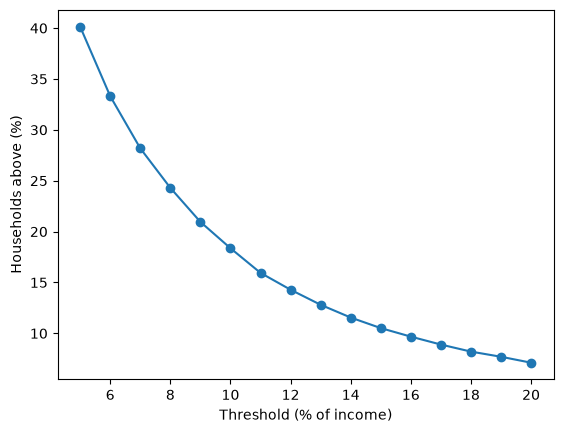

In [7]:
import numpy as np

grid_values = np.arange(th["grid_min"], th["grid_max"] + 1e-9, th["grid_step"])
grid = affordability.threshold_table(ies, grid_values)
plt.plot(grid["threshold"] * 100, grid["share_above"] * 100, marker="o")
plt.xlabel("Threshold (% of income)")
plt.ylabel("Households above (%)")
plt.show()

### Limits 
1. Households with no electricity bill (about 23%) are excluded. They may have free electricity, another source, or no connection, so the burden on households that ration or cannot afford electricity is hidden.
2. The survey is from 2022/23 and tariffs have risen since, so today's burden is higher.
3. Shares are sensitive to very low reported incomes, so I report medians and group totals alongside averages.
4. The 10% line is a convention, not a fact, so I show 8%, 10% and 12%.